# ---> CreditWise Loan System

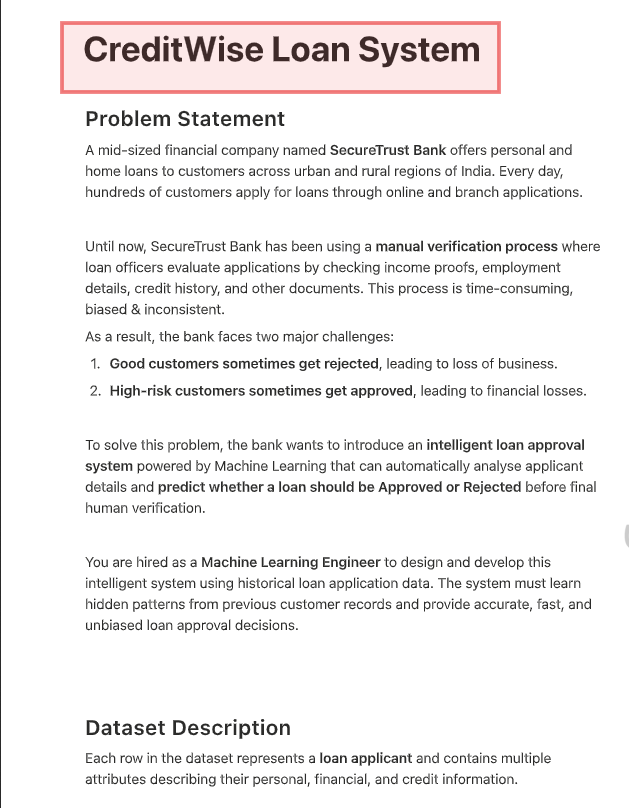

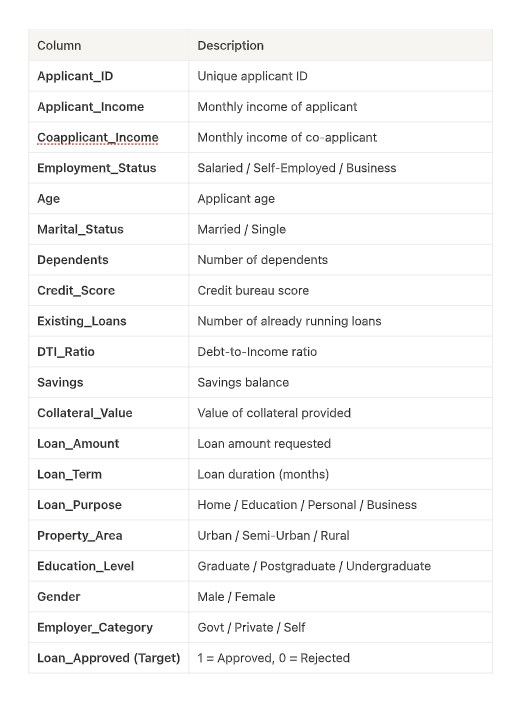

### Binary Classification Model for Credit Risk Assessment

#### 1. Dataset Information

Total Samples: 1,000

Input Features: 19

Output/Target Column: 1

#### 2. Problem Type

Binary Classification

The model predicts one of two possible classes:

Yes (1): Loan Approved

No (0): Loan Rejected

#### 3. Machine Learning Algorithms
The following classification algorithms will be explored for loan approval prediction:

Logistic Regression

K-Nearest Neighbors (KNN)

Naive Bayes

In [3]:
import pandas as pd
import numpy as np

import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split

In [4]:
df = pd.read_csv("loan_approval_data.csv")
df.head()

,Applicant_ID,Applicant_Income,Coapplicant_Income,Employment_Status,Age,Marital_Status,Dependents,Credit_Score,Existing_Loans,DTI_Ratio,Savings,Collateral_Value,Loan_Amount,Loan_Term,Loan_Purpose,Property_Area,Education_Level,Gender,Employer_Category,Loan_Approved
0,1.0,17795.0,1387.0,Salaried,51.0,Married,0.0,637.0,4.0,0.53,19403.0,45638.0,16619.0,84.0,Personal,Urban,Not Graduate,Female,Private,No
1,2.0,2860.0,2679.0,Salaried,46.0,Married,3.0,621.0,2.0,0.30,2580.0,49272.0,38687.0,NaN,Car,Semiurban,Graduate,NaN,Private,No
2,3.0,7390.0,2106.0,Salaried,25.0,Single,2.0,674.0,4.0,0.20,13844.0,6908.0,27943.0,72.0,NaN,Urban,NaN,Female,Government,Yes
3,4.0,13964.0,8173.0,Salaried,40.0,Married,2.0,579.0,3.0,0.31,9553.0,10844.0,27819.0,60.0,Business,Rural,Graduate,Female,Government,No
4,5.0,13284.0,4223.0,Self-employed,31.0,Single,2.0,721.0,1.0,0.29,9386.0,37629.0,12741.0,72.0,Car,NaN,Graduate,Male,Private,Yes


In [5]:
df.info() 

# m ---> 1000 (rows)
# n ---> 19 (features)
# ---> 1  (output features)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 20 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Applicant_ID        950 non-null    float64
 1   Applicant_Income    950 non-null    float64
 2   Coapplicant_Income  950 non-null    float64
 3   Employment_Status   950 non-null    object 
 4   Age                 950 non-null    float64
 5   Marital_Status      950 non-null    object 
 6   Dependents          950 non-null    float64
 7   Credit_Score        950 non-null    float64
 8   Existing_Loans      950 non-null    float64
 9   DTI_Ratio           950 non-null    float64
 10  Savings             950 non-null    float64
 11  Collateral_Value    950 non-null    float64
 12  Loan_Amount         950 non-null    float64
 13  Loan_Term           950 non-null    float64
 14  Loan_Purpose        950 non-null    object 
 15  Property_Area       950 non-null    object 
 16  Educati

#### --> Handle missing values

In [6]:
categorical_col = df.select_dtypes(include = ["object"]).columns  # select_dtype is select the all col_ which have (object/categorical) data
numerical_col = df.select_dtypes(include = ["float64"]).columns  # select_dtype is select the all col_ which have (float64/numerical) data

In [7]:
# for filling the null val_ use sklearn_simple_imputer
from sklearn.impute import SimpleImputer

num_imp = SimpleImputer(strategy = "mean")
df[numerical_col] = num_imp.fit_transform(df[numerical_col])

cat_imp = SimpleImputer(strategy="most_frequent")
df[categorical_col] = cat_imp.fit_transform(df[categorical_col])

In [8]:
df.head()

,Applicant_ID,Applicant_Income,Coapplicant_Income,Employment_Status,Age,Marital_Status,Dependents,Credit_Score,Existing_Loans,DTI_Ratio,Savings,Collateral_Value,Loan_Amount,Loan_Term,Loan_Purpose,Property_Area,Education_Level,Gender,Employer_Category,Loan_Approved
0,1.0,17795.0,1387.0,Salaried,51.0,Married,0.0,637.0,4.0,0.53,19403.0,45638.0,16619.0,84.0,Personal,Urban,Not Graduate,Female,Private,No
1,2.0,2860.0,2679.0,Salaried,46.0,Married,3.0,621.0,2.0,0.30,2580.0,49272.0,38687.0,48.0,Car,Semiurban,Graduate,Male,Private,No
2,3.0,7390.0,2106.0,Salaried,25.0,Single,2.0,674.0,4.0,0.20,13844.0,6908.0,27943.0,72.0,Business,Urban,Graduate,Female,Government,Yes
3,4.0,13964.0,8173.0,Salaried,40.0,Married,2.0,579.0,3.0,0.31,9553.0,10844.0,27819.0,60.0,Business,Rural,Graduate,Female,Government,No
4,5.0,13284.0,4223.0,Self-employed,31.0,Single,2.0,721.0,1.0,0.29,9386.0,37629.0,12741.0,72.0,Car,Urban,Graduate,Male,Private,Yes


In [9]:
df.info()  # we can see the Non-Null Count is not (1000/1000)
# check null val_
df.isnull().sum()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 20 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Applicant_ID        1000 non-null   float64
 1   Applicant_Income    1000 non-null   float64
 2   Coapplicant_Income  1000 non-null   float64
 3   Employment_Status   1000 non-null   object 
 4   Age                 1000 non-null   float64
 5   Marital_Status      1000 non-null   object 
 6   Dependents          1000 non-null   float64
 7   Credit_Score        1000 non-null   float64
 8   Existing_Loans      1000 non-null   float64
 9   DTI_Ratio           1000 non-null   float64
 10  Savings             1000 non-null   float64
 11  Collateral_Value    1000 non-null   float64
 12  Loan_Amount         1000 non-null   float64
 13  Loan_Term           1000 non-null   float64
 14  Loan_Purpose        1000 non-null   object 
 15  Property_Area       1000 non-null   object 
 16  Educati

Applicant_ID          0
Applicant_Income      0
Coapplicant_Income    0
Employment_Status     0
Age                   0
Marital_Status        0
Dependents            0
Credit_Score          0
Existing_Loans        0
DTI_Ratio             0
Savings               0
Collateral_Value      0
Loan_Amount           0
Loan_Term             0
Loan_Purpose          0
Property_Area         0
Education_Level       0
Gender                0
Employer_Category     0
Loan_Approved         0
dtype: int64

#### ---> EDA - exploratory data analysis

Text(0.5, 1.0, 'Is Loan approved or not?')

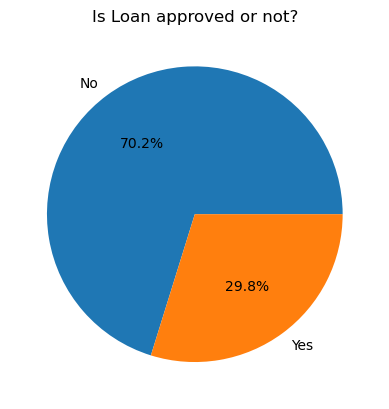

In [10]:
# how balance our classes are?

classes_count = df["Loan_Approved"].value_counts() # "Loan_Approved_"---> ountup_col

plt.pie(classes_count, labels= ["No", "Yes"], autopct="%1.1f%%")
plt.title("Is Loan approved or not?")

[Text(0, 0, '621'), Text(0, 0, '379')]

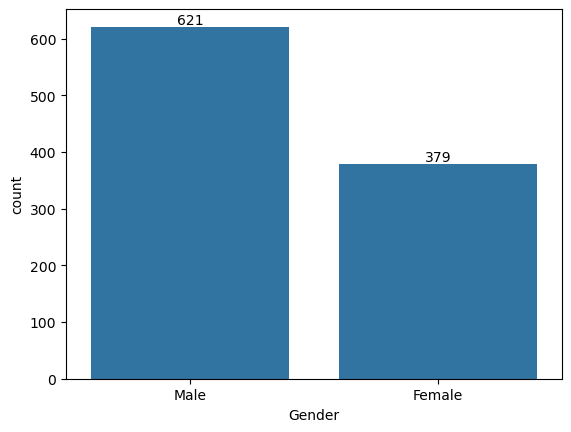

In [11]:
# gender_count

gn_count = df["Gender"].value_counts()
ax = sns.barplot(gn_count)
ax.bar_label(ax.containers[0])

[Text(0, 0, '722'), Text(0, 0, '278')]

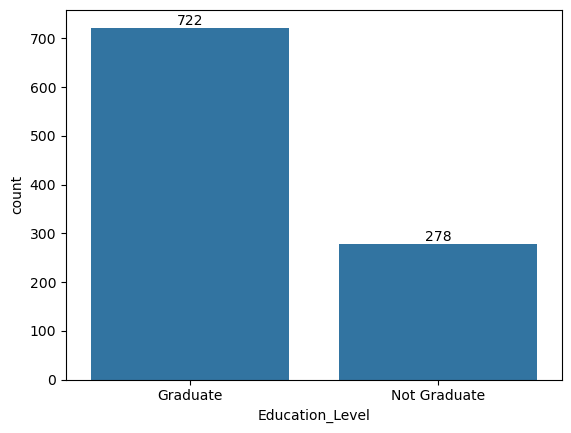

In [12]:
edu_cnt = df["Education_Level"].value_counts()
ax = sns.barplot(edu_cnt)
ax.bar_label(ax.containers [0])

<Axes: xlabel='Applicant_Income', ylabel='Count'>

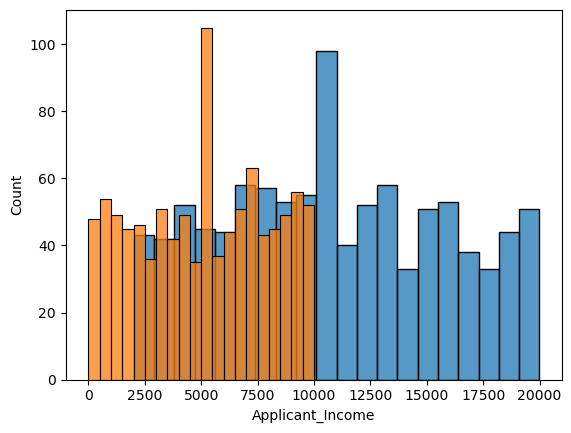

In [13]:
# analyze Income

sns.histplot(
    data = df,
    x = "Applicant_Income",
    bins = 20
)
sns.histplot(
    data = df,
    x = "Coapplicant_Income",
    bins = 20
)

<Axes: xlabel='Loan_Approved', ylabel='Applicant_Income'>

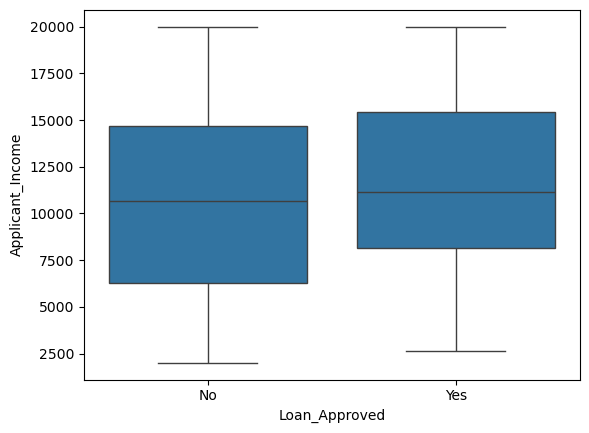

In [14]:
# outliers - box plots

sns.boxplot(
    data = df,
    x = "Loan_Approved",
    y = "Applicant_Income"
)

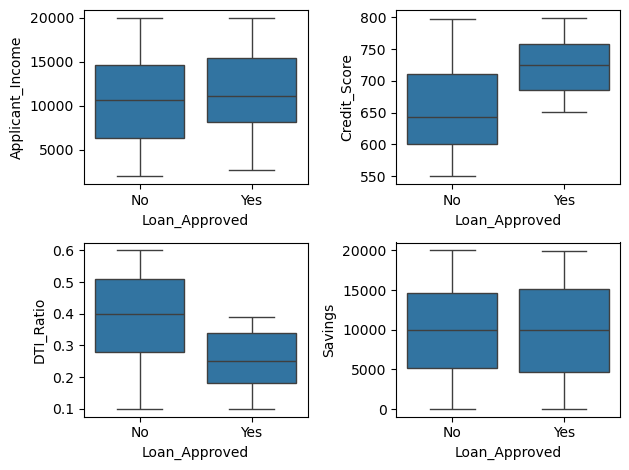

In [15]:
fig, axes = plt.subplots(2, 2)

sns.boxplot(ax=axes[0, 0], data = df, x = "Loan_Approved", y = "Applicant_Income")
sns.boxplot(ax=axes[0, 1], data = df, x = "Loan_Approved", y = "Credit_Score")
sns.boxplot(ax=axes[1, 0], data = df, x = "Loan_Approved", y = "DTI_Ratio")
sns.boxplot(ax=axes[1, 1], data = df, x = "Loan_Approved", y = "Savings")

plt.tight_layout()




# Outlier's --> there is no outlier in this data , so we skip the process of removing the outliers\



<Axes: xlabel='Credit_Score', ylabel='Count'>

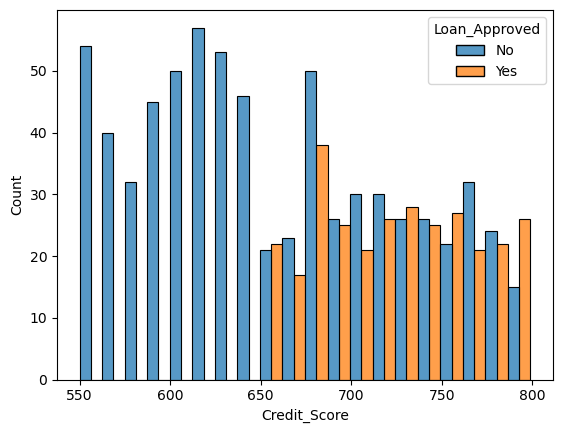

In [16]:
# Credit Score with Loan Approved

sns.histplot(
    data = df,
    x="Credit_Score",
    hue = "Loan_Approved",
    bins=20,
    multiple = "dodge"
)

<Axes: xlabel='Applicant_Income', ylabel='Count'>

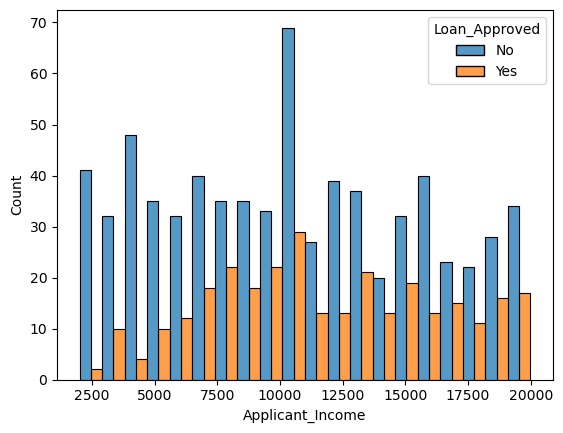

In [17]:
# Credit Score with Loan Approved

sns.histplot(
    data = df,
    x="Applicant_Income",
    hue = "Loan_Approved",
    bins=20,
    multiple = "dodge"
)

In [18]:
# 

In [19]:
# Removing unnessery features like- Applicant Id

df = df.drop("Applicant_ID", axis = 1)



In [20]:
df.head()

,Applicant_Income,Coapplicant_Income,Employment_Status,Age,Marital_Status,Dependents,Credit_Score,Existing_Loans,DTI_Ratio,Savings,Collateral_Value,Loan_Amount,Loan_Term,Loan_Purpose,Property_Area,Education_Level,Gender,Employer_Category,Loan_Approved
0,17795.0,1387.0,Salaried,51.0,Married,0.0,637.0,4.0,0.53,19403.0,45638.0,16619.0,84.0,Personal,Urban,Not Graduate,Female,Private,No
1,2860.0,2679.0,Salaried,46.0,Married,3.0,621.0,2.0,0.30,2580.0,49272.0,38687.0,48.0,Car,Semiurban,Graduate,Male,Private,No
2,7390.0,2106.0,Salaried,25.0,Single,2.0,674.0,4.0,0.20,13844.0,6908.0,27943.0,72.0,Business,Urban,Graduate,Female,Government,Yes
3,13964.0,8173.0,Salaried,40.0,Married,2.0,579.0,3.0,0.31,9553.0,10844.0,27819.0,60.0,Business,Rural,Graduate,Female,Government,No
4,13284.0,4223.0,Self-employed,31.0,Single,2.0,721.0,1.0,0.29,9386.0,37629.0,12741.0,72.0,Car,Urban,Graduate,Male,Private,Yes


## ================================================================

# next step ---> Encoding

## ---> One-Hot Encoding 
### One-Hot Encoding is a data preprocessing technique used to convert categorical (text) variables into numerical binary (0 and 1) columns, 
## where each unique category gets its own column

## ---> Label Encoding
### Label Encoding is a technique used to convert categorical data (text values) into numerical values so that Machine Learning algorithms can process them.


### ===> Difference Between Label Encoding and One-Hot Encoding
| Feature           | **Label Encoding**                  | **One-Hot Encoding**                     |
| ----------------- | ----------------------------------- | ---------------------------------------- |
| Conversion        | Each category gets **one number**   | Each category gets a **separate column** |
| Example           | Red → 0, Blue → 1, Green → 2        | Red → `[1,0,0]`                          |
| Number of columns | **1 column**                        | **Multiple columns**                     |
| Creates order?    | Yes, it may imply an order          | **No order**                             |
| Best for          | **Ordinal data**                    | **Nominal data**                         |
| Example           | Low < Medium < High                 | Red, Blue, Green                         |
| Main disadvantage | Can create false relationship/order | Can create many columns                  |



### Feature Encoding

Feature encoding converts categorical data into numerical form for Machine Learning models.

#### 1. Label / Ordinal Encoding

Assigns numbers to categories with a meaningful order.

**Example:**

| Education     | Value |
| ------------- | ----- |
| Undergraduate | 0     |
| Postgraduate  | 1     |
| PhD           | 2     |

**Use:** Ordinal data (education level, satisfaction).

#### 2. One-Hot Encoding

Creates separate binary columns (0 and 1) for categories without a natural order.

**Example:**

| Gender | Male | Female |
| ------ | ---- | ------ |
| Male   | 1    | 0      |
| Female | 0    | 1      |

**Use:** Nominal data (gender, city, marital status).

#### Key Difference

- **Ordinal Encoding:** Represents ordered categories with numbers.
- **One-Hot Encoding:** Represents unordered categories with binary columns.

**CreditWise Application:** Encode categorical features before training the loan approval prediction model.

Add CreditWise Encoding ExamplesClarify Encoding Method Selection

In [21]:
from sklearn.preprocessing import LabelEncoder , OneHotEncoder

le = LabelEncoder()
df["Education_Level"] = le.fit_transform(df["Education_Level"])
df["Loan_Approved"] = le.fit_transform(df["Loan_Approved"])


In [22]:
df.head(10)

,Applicant_Income,Coapplicant_Income,Employment_Status,Age,Marital_Status,Dependents,Credit_Score,Existing_Loans,DTI_Ratio,Savings,Collateral_Value,Loan_Amount,Loan_Term,Loan_Purpose,Property_Area,Education_Level,Gender,Employer_Category,Loan_Approved
0,17795.0,1387.000000,Salaried,51.0,Married,0.0,637.0,4.0,0.530000,19403.0,45638.0,16619.0,84.0,Personal,Urban,1,Female,Private,0
1,2860.0,2679.000000,Salaried,46.0,Married,3.0,621.0,2.0,0.300000,2580.0,49272.0,38687.0,48.0,Car,Semiurban,0,Male,Private,0
2,7390.0,2106.000000,Salaried,25.0,Single,2.0,674.0,4.0,0.200000,13844.0,6908.0,27943.0,72.0,Business,Urban,0,Female,Government,1
3,13964.0,8173.000000,Salaried,40.0,Married,2.0,579.0,3.0,0.310000,9553.0,10844.0,27819.0,60.0,Business,Rural,0,Female,Government,0
4,13284.0,4223.000000,Self-employed,31.0,Single,2.0,721.0,1.0,0.290000,9386.0,37629.0,12741.0,72.0,Car,Urban,0,Male,Private,1
5,8265.0,4831.000000,Salaried,53.0,Single,1.0,602.0,1.0,0.560000,19522.0,2911.0,9798.0,36.0,Home,Semiurban,0,Male,Unemployed,0
6,18850.0,2768.000000,Salaried,58.0,Married,0.0,687.0,0.0,0.480000,14635.0,8991.0,26143.0,24.0,Home,Rural,0,Male,Private,0
7,6426.0,3186.000000,Salaried,47.0,Married,2.0,636.0,4.0,0.347263,671.0,11572.0,33747.0,84.0,Personal,Rural,0,Female,Private,0
8,16423.0,5082.455789,Salaried,54.0,Married,1.0,729.0,0.0,0.590000,777.0,43066.0,34651.0,36.0,Home,Semiurban,0,Male,Private,0
9,13363.0,2599.000000,Contract,35.0,Single,3.0,726.0,1.0,0.347263,3022.0,29693.0,22182.0,60.0,Personal,Rural,0,Female,Government,1


In [23]:
# one-hot-encoding

cols = ["Employment_Status", "Marital_Status", "Loan_Purpose", "Property_Area", "Gender", "Employer_Category"]

ohe = OneHotEncoder(drop="first", sparse_output=False, handle_unknown="ignore")

encoded = ohe.fit_transform(df[cols])

encoded_df = pd.DataFrame(encoded, columns=ohe.get_feature_names_out(cols), index=df.index)

df = pd.concat([df.drop(columns=cols), encoded_df], axis=1)

In [24]:
df.head()

,Applicant_Income,Coapplicant_Income,Age,Dependents,Credit_Score,Existing_Loans,DTI_Ratio,Savings,Collateral_Value,Loan_Amount,...,Loan_Purpose_Education,Loan_Purpose_Home,Loan_Purpose_Personal,Property_Area_Semiurban,Property_Area_Urban,Gender_Male,Employer_Category_Government,Employer_Category_MNC,Employer_Category_Private,Employer_Category_Unemployed
0,17795.0,1387.0,51.0,0.0,637.0,4.0,0.53,19403.0,45638.0,16619.0,...,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0
1,2860.0,2679.0,46.0,3.0,621.0,2.0,0.30,2580.0,49272.0,38687.0,...,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0
2,7390.0,2106.0,25.0,2.0,674.0,4.0,0.20,13844.0,6908.0,27943.0,...,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0
3,13964.0,8173.0,40.0,2.0,579.0,3.0,0.31,9553.0,10844.0,27819.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
4,13284.0,4223.0,31.0,2.0,721.0,1.0,0.29,9386.0,37629.0,12741.0,...,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0


In [25]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 28 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   Applicant_Income                 1000 non-null   float64
 1   Coapplicant_Income               1000 non-null   float64
 2   Age                              1000 non-null   float64
 3   Dependents                       1000 non-null   float64
 4   Credit_Score                     1000 non-null   float64
 5   Existing_Loans                   1000 non-null   float64
 6   DTI_Ratio                        1000 non-null   float64
 7   Savings                          1000 non-null   float64
 8   Collateral_Value                 1000 non-null   float64
 9   Loan_Amount                      1000 non-null   float64
 10  Loan_Term                        1000 non-null   float64
 11  Education_Level                  1000 non-null   int64  
 12  Loan_Approved        

In [26]:
df.describe()

,Applicant_Income,Coapplicant_Income,Age,Dependents,Credit_Score,Existing_Loans,DTI_Ratio,Savings,Collateral_Value,Loan_Amount,...,Loan_Purpose_Education,Loan_Purpose_Home,Loan_Purpose_Personal,Property_Area_Semiurban,Property_Area_Urban,Gender_Male,Employer_Category_Government,Employer_Category_MNC,Employer_Category_Private,Employer_Category_Unemployed
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,...,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000
mean,10852.571579,5082.455789,39.971579,1.474737,676.033684,1.950526,0.347263,9940.452632,24802.792632,20522.825263,...,0.181000,0.190000,0.178000,0.189000,0.517000,0.621000,0.202000,0.144000,0.422000,0.097000
std,4933.339492,2868.563488,10.857445,1.077058,69.537662,1.370603,0.140683,5712.189236,13982.086562,11212.555805,...,0.385211,0.392497,0.382704,0.391705,0.499961,0.485381,0.401693,0.351265,0.494126,0.296106
min,2009.000000,1.000000,21.000000,0.000000,550.000000,0.000000,0.100000,65.000000,36.000000,1015.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,6857.000000,2701.250000,31.000000,1.000000,618.000000,1.000000,0.230000,4964.000000,13166.000000,10478.250000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,10852.571579,5082.455789,39.971579,1.237368,676.033684,2.000000,0.347263,9940.452632,24802.792632,20522.825263,...,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000
75%,14973.250000,7452.750000,49.000000,2.000000,735.000000,3.000000,0.470000,14784.750000,36396.000000,29683.250000,...,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000,0.000000,0.000000,1.000000,0.000000
max,19988.000000,9996.000000,59.000000,3.000000,799.000000,4.000000,0.600000,19996.000000,49954.000000,39995.000000,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


### Correlation Heatmap

It is a visual representation of the relationships between numerical variables in a dataset.

It shows Correlation coefficient (r) between two numeric variables

· ranges from -1 to 1

· 1 is perfect positive correlation
· -1 is perfect negative correlation
· 0 is no linear correlation

#### benefit why we use Correlation_heatmap
1. Quick Insights
2. Detect Multi collinearity
   1. PCA
   2. dim-reduction
   3. feature relation
3. Data exploration
4. pre processing

<Axes: >

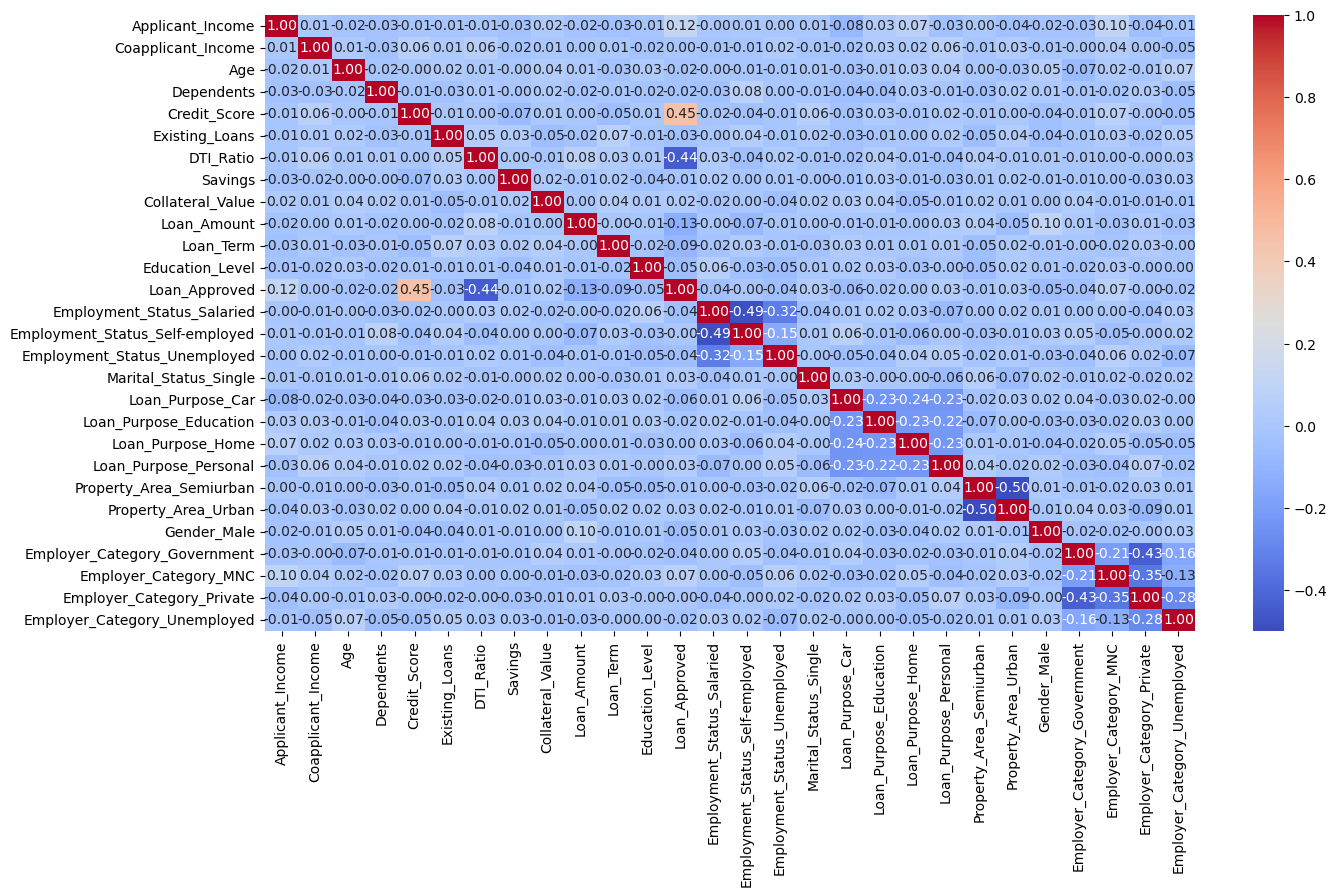

In [33]:
nums_cols = df.select_dtypes(include="number")
corr_matrix = nums_cols.corr()    # shows the relationship b/t each feature's/colm_


plt.figure(figsize=(15, 8))
sns.heatmap(
    corr_matrix,
    annot = True,
    fmt = ".2f",
    cmap = "coolwarm"
)

In [31]:
nums_cols.corr()["Loan_Approved"].sort_values(ascending=False)

Loan_Approved                      1.000000
Credit_Score                       0.451175
Applicant_Income                   0.119796
Employer_Category_MNC              0.069049
Loan_Purpose_Personal              0.034043
Marital_Status_Single              0.030182
Property_Area_Urban                0.025963
Collateral_Value                   0.021868
Coapplicant_Income                 0.004230
Loan_Purpose_Home                  0.002118
Employment_Status_Self-employed   -0.001337
Employer_Category_Private         -0.003347
Property_Area_Semiurban           -0.012967
Savings                           -0.013437
Loan_Purpose_Education            -0.016684
Employer_Category_Unemployed      -0.021468
Age                               -0.022343
Dependents                        -0.023811
Existing_Loans                    -0.034794
Employer_Category_Government      -0.039187
Employment_Status_Salaried        -0.041428
Employment_Status_Unemployed      -0.044464
Education_Level                 

## Train-Test-Split + Feature Scaling

In [35]:
X = df.drop("Loan_Approved", axis=1)
y = df["Loan_Approved"]


In [36]:
# There is big data and high no. of features (27 features)  so can't use Knn 

# train-test-split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 42)

In [40]:
#  feature_scaling
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

## Train & Evaluate Models

In [44]:
# logistic regression

from sklearn.linear_model import LogisticRegression

log_model = LogisticRegression()
log_model.fit(X_train_scaled, y_train)


y_pred = log_model.predict(X_test_scaled)

# Evalution

# 1. Good customers sometimes get rejected, leading to loss of business.
# 2. High-risk customers sometimes get approved, leading to financial losses.

# acc_ to above lines (1,2) , so priority give for encoding is precision_score then recall f1_score for this data

from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score

print("precision:" , precision_score(y_test, y_pred))
print("Recall   :" , recall_score(y_test, y_pred))
print("F1_score :" , f1_score(y_test, y_pred))
print("Accuracy :" , accuracy_score(y_test, y_pred))
print("CM:" , confusion_matrix(y_test, y_pred))


precision: 0.7833333333333333
Recall   : 0.7704918032786885
F1_score : 0.7768595041322314
Accuracy : 0.865
CM: [[126  13]
 [ 14  47]]


In [49]:
# KNN
from sklearn.neighbors import KNeighborsClassifier

from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score

knn_model = KNeighborsClassifier(n_neighbors=5)
knn_model.fit(X_train_scaled, y_train)


y_pred = knn_model.predict(X_test_scaled)


print("precision:" , precision_score(y_test, y_pred))
print("Recall   :" , recall_score(y_test, y_pred))
print("F1_score :" , f1_score(y_test, y_pred))
print("Accuracy :" , accuracy_score(y_test, y_pred))
print("CM:" , confusion_matrix(y_test, y_pred))


# here we see knn perform worst as compare LogisticRegression

precision: 0.6274509803921569
Recall   : 0.5245901639344263
F1_score : 0.5714285714285714
Accuracy : 0.76
CM: [[120  19]
 [ 29  32]]


In [50]:
# Naive Bayes

from sklearn.naive_bayes import GaussianNB

nb_model = GaussianNB()
nb_model.fit(X_train_scaled, y_train)

y_pred = nb_model.predict(X_test_scaled)

print("precision:" , precision_score(y_test, y_pred))
print("Recall   :" , recall_score(y_test, y_pred))
print("F1_score :" , f1_score(y_test, y_pred))
print("Accuracy :" , accuracy_score(y_test, y_pred))
print("CM:" , confusion_matrix(y_test, y_pred))


precision: 0.8035714285714286
Recall   : 0.7377049180327869
F1_score : 0.7692307692307693
Accuracy : 0.865
CM: [[128  11]
 [ 16  45]]


# Best Model on the basis of Precision => Naive Bayes

In [ ]:
## ===============================================

# Feature Engineering

sometimes data is skewed then we use log funtion 

for more ( effective features --> (DTI_ratio, Credit_score, etc)) use square of it 


In [57]:
# Add or Tranform features
df["DTI_Ratio_sq"]= df["DTI_Ratio"] ** 2
df["Credit_Score_sq"] = df["Credit_Score"] ** 2

# df["Applicant_Income_log"] = np.log1p(df["Applicant_Income"])

X = df.drop(columns=["Loan_Approved", "Credit_Score", "DTI_Ratio"])
y = df["Loan_Approved"]

# Train test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Scaling
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [59]:
# Logistic_reg
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score

log_model = LogisticRegression()
log_model.fit(X_train_scaled, y_train)
y_pred = log_model.predict(X_test_scaled)
print("precision:" , precision_score(y_test, y_pred))
print("Recall   :" , recall_score(y_test, y_pred))
print("F1_score :" , f1_score(y_test, y_pred))
print("Accuracy :" , accuracy_score(y_test, y_pred))
print("CM:" , confusion_matrix(y_test, y_pred))



# KNN
print("----------> Knn")
from sklearn.neighbors import KNeighborsClassifier
knn_model = KNeighborsClassifier(n_neighbors=5)
knn_model.fit(X_train_scaled, y_train)
y_pred = knn_model.predict(X_test_scaled)

print("precision:" , precision_score(y_test, y_pred))
print("Recall   :" , recall_score(y_test, y_pred))
print("F1_score :" , f1_score(y_test, y_pred))
print("Accuracy :" , accuracy_score(y_test, y_pred))
print("CM:" , confusion_matrix(y_test, y_pred))




# Naive Bayes
print("----------> Naive Bayes")
from sklearn.naive_bayes import GaussianNB
nb_model = GaussianNB()
nb_model.fit(X_train_scaled, y_train)
y_pred = nb_model.predict(X_test_scaled)

print("precision:" , precision_score(y_test, y_pred))
print("Recall   :" , recall_score(y_test, y_pred))
print("F1_score :" , f1_score(y_test, y_pred))
print("Accuracy :" , accuracy_score(y_test, y_pred))
print("CM:" , confusion_matrix(y_test, y_pred))

precision: 0.7846153846153846
Recall   : 0.8360655737704918
F1_score : 0.8095238095238095
Accuracy : 0.88
CM: [[125  14]
 [ 10  51]]
----------> Knn
precision: 0.6730769230769231
Recall   : 0.5737704918032787
F1_score : 0.6194690265486725
Accuracy : 0.785
CM: [[122  17]
 [ 26  35]]
----------> Naive Bayes
precision: 0.8113207547169812
Recall   : 0.7049180327868853
F1_score : 0.7543859649122807
Accuracy : 0.86
CM: [[129  10]
 [ 18  43]]


### Resume Project Description

- Built a supervised Machine Learning pipeline to predict loan approval using **Logistic Regression, K-Nearest Neighbors (KNN), and Naive Bayes**.
- Performed **Exploratory Data Analysis (EDA), feature engineering, and binary classification** to prepare applicant data and train models.
- Evaluated model performance using **Precision, Recall, and F1-score**.

### Key Skills & Keywords
Python | Machine Learning | EDA | Feature Engineering | Binary Classification | Model Evaluation | Scikit-learn

### Deployment
**Streamlit:** Deploy the trained model as an interactive web application for loan approval predictions.